## RT-DETR

### Instalación

In [13]:
import json
import os
import subprocess
import sys
import time
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from ultralytics import YOLO

warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)

Dispositivo: cuda


In [ ]:
# Clona el repositorio oficial de RT-DETR (si no existe) y lo añade al path para poder importar src
REPO = "RT-DETR/rtdetrv2_pytorch"

if not os.path.exists("RT-DETR"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git"], check=True)
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))

# Imports del repositorio (solo funcionan después de añadir el path)
from src.core import YAMLConfig
from src.core.yaml_utils import load_config
from load_rtdetr import load_rtdetr

In [ ]:
# Descarga los pesos oficiales de RT-DETR v2 tamaño S (r18) entrenados en COCO en weights/.
# Son el punto de partida del entrenamiento con las matrículas (opción -t del comando de entrenamiento)
model, postprocessor = load_rtdetr(family="v2", size="s", device=DEVICE)

Cargando RT-DETR familia 'v2', tamaño 's' en cuda
No se detectaron los pesos del modelo v2/r18. Se estan descargando y guardando en weights/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth


Downloading: "https://github.com/lyuwenyu/storage/releases/download/v0.1/ResNet18_vd_pretrained_from_paddle.pth" to C:\Users\alici/.cache\torch\hub\checkpoints\ResNet18_vd_pretrained_from_paddle.pth
100.0%


Load PResNet18 state_dict


### Entrenamiento

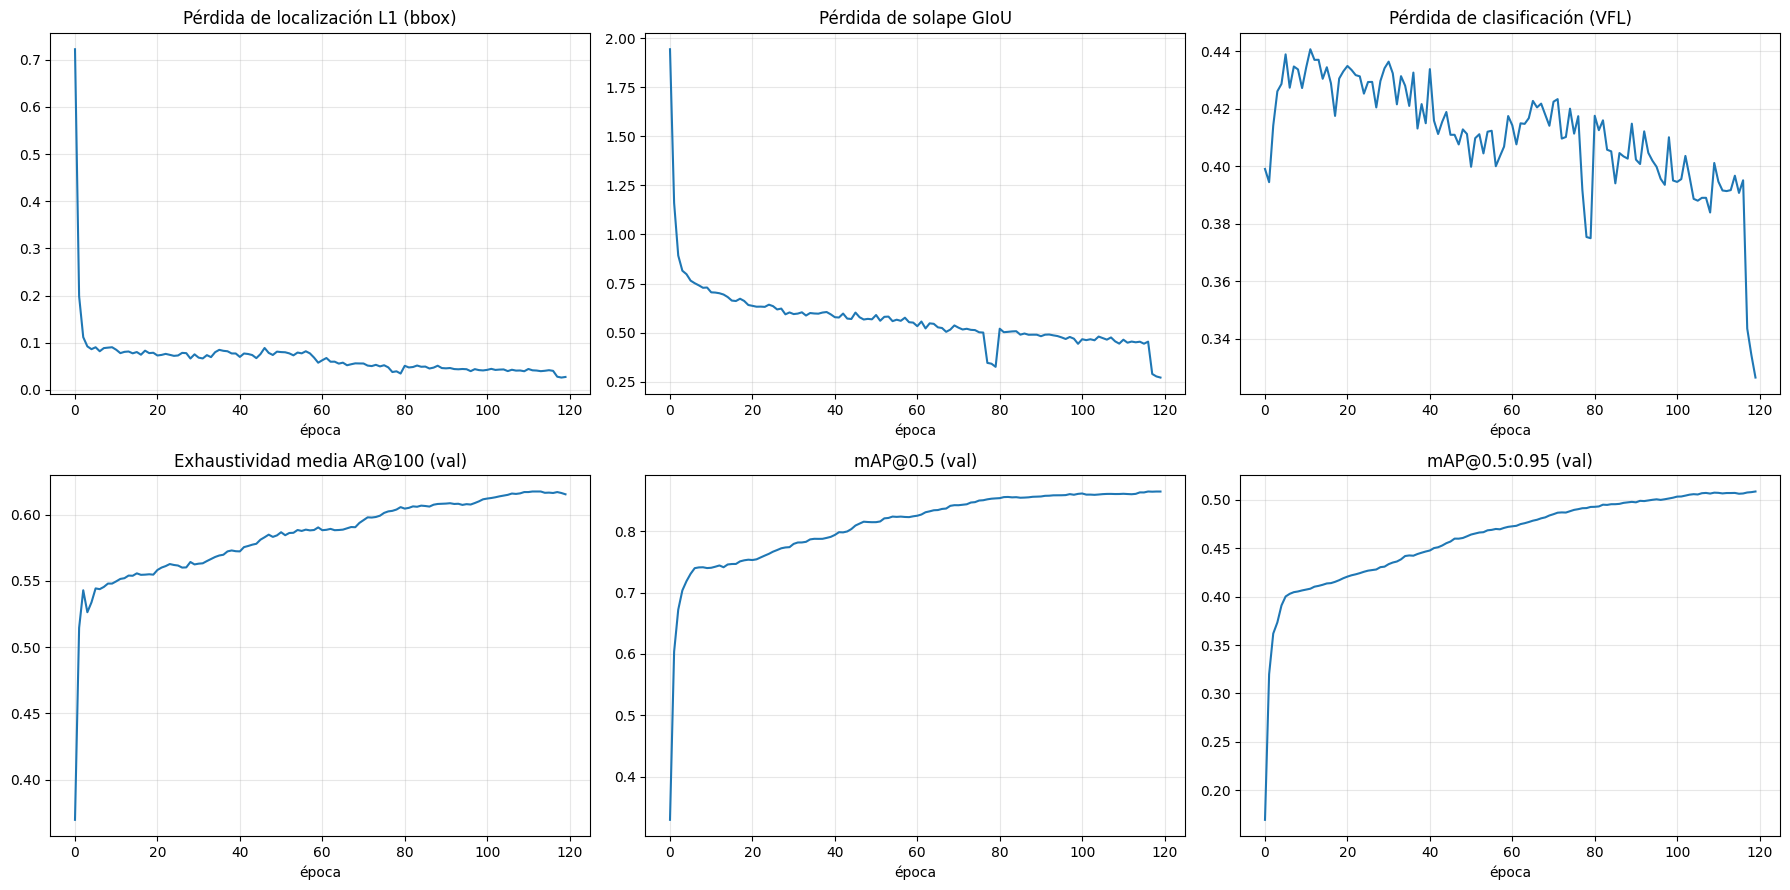

Épocas entrenadas: 120 | mejor época: 119 (mAP50 = 0.865, mAP50-95 = 0.509)


In [ ]:
RUN_DIR = Path("runs_rtdetr/rtdetrv2_r18_matriculas")

# log.txt: una línea JSON por época con las pérdidas de entrenamiento y las métricas COCO en validación
log = pd.DataFrame([json.loads(l) for l in open(RUN_DIR / "log.txt")])
metricas_coco = ["AP50_95", "AP50", "AP75", "APs", "APm", "APl",
                 "AR1", "AR10", "AR100", "ARs", "ARm", "ARl"]
log = pd.concat([log, pd.DataFrame(log["test_coco_eval_bbox"].tolist(), columns=metricas_coco)], axis=1)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
graficas = [
    ("train_loss_bbox", "Pérdida de localización L1 (bbox)"),
    ("train_loss_giou", "Pérdida de solape GIoU"),
    ("train_loss_vfl", "Pérdida de clasificación (VFL)"),
    ("AR100", "Exhaustividad media AR@100 (val)"),
    ("AP50", "mAP@0.5 (val)"),
    ("AP50_95", "mAP@0.5:0.95 (val)"),
]
for ax, (col, titulo) in zip(axes.flat, graficas):
    ax.plot(log["epoch"], log[col])
    ax.set_title(titulo)
    ax.set_xlabel("época")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_DIR / "curvas_entrenamiento.png", dpi=150)
plt.show()

mejor = log.loc[log["AP50_95"].idxmax()]
print(f"Épocas entrenadas: {len(log)} | mejor época: {int(mejor['epoch'])} "
      f"(mAP50 = {mejor['AP50']:.3f}, mAP50-95 = {mejor['AP50_95']:.3f})")

### Comparación con YOLO

In [ ]:
# RT-DETR
load_config.__defaults__[0].clear()
cfg = YAMLConfig("configs_matriculas/rtdetrv2_r18vd_matriculas.yml")
ckpt = torch.load(RUN_DIR / "best.pth", map_location="cpu", weights_only=False)
cfg.model.load_state_dict(ckpt["ema"]["module"])
rtdetr = cfg.model.deploy().to(DEVICE).eval()
rtdetr_post = cfg.postprocessor.deploy().to(DEVICE)

# YOLO
yolo = YOLO("runs/matriculas_yolo11n_1280_min001/weights/best.pt")

In [ ]:
TEST_IMGS = sorted(Path("dataset_yolo/images/test").iterdir())
TEST_LABELS = Path("dataset_yolo/labels/test")


# Cada función devuelve (cajas xyxy en píxeles, confianzas) para una imagen BGR
@torch.no_grad()
def predecir_rtdetr(img):
    h, w = img.shape[:2]
    im = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    _, cajas, scores = rtdetr_post(rtdetr(x), torch.tensor([[w, h]], device=DEVICE))
    return cajas[0].cpu().numpy(), scores[0].cpu().numpy()


def predecir_yolo(img):
    r = yolo.predict(img, imgsz=1280, conf=0.001, device=0, verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()


# Cajas reales de una imagen (etiquetas YOLO normalizadas -> píxeles xyxy)
def cajas_reales(img_path, W, H):
    filas = [list(map(float, l.split()))[1:] for l in (TEST_LABELS / f"{img_path.stem}.txt").read_text().splitlines()]
    return np.array([[(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]
                     for xc, yc, w, h in filas]).reshape(-1, 4)


# IoU entre todas las cajas de a y todas las de b
def iou_matriz(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


# Empareja predicciones con matrículas reales (IoU >= 0.5, de mayor a menor confianza)
def evaluar_test(predecir):
    scores_todas, es_tp, n_reales, tiempos = [], [], 0, []
    for p in TEST_IMGS:
        img = cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_COLOR)
        H, W = img.shape[:2]
        reales = cajas_reales(p, W, H)
        n_reales += len(reales)

        torch.cuda.synchronize(); t0 = time.perf_counter()
        cajas, scores = predecir(img)
        torch.cuda.synchronize(); tiempos.append((time.perf_counter() - t0) * 1000)

        orden = np.argsort(-scores)
        cajas, scores = cajas[orden], scores[orden]
        ious = iou_matriz(cajas, reales) if len(cajas) and len(reales) else np.zeros((len(cajas), len(reales)))
        usadas = np.zeros(len(reales), bool)
        for i in range(len(cajas)):
            libres = np.where(~usadas)[0]
            tp = False
            if len(libres):
                j = libres[np.argmax(ious[i, libres])]
                if ious[i, j] >= 0.5:
                    usadas[j] = tp = True
            scores_todas.append(scores[i])
            es_tp.append(tp)

    return {"scores": np.array(scores_todas), "tp": np.array(es_tp),
            "n_reales": n_reales, "ms": float(np.median(tiempos[5:]))}  # sin las 5 primeras (calentamiento)


resultados = {"YOLO11n (1280)": evaluar_test(predecir_yolo),
              "RT-DETR r18 (640)": evaluar_test(predecir_rtdetr)}

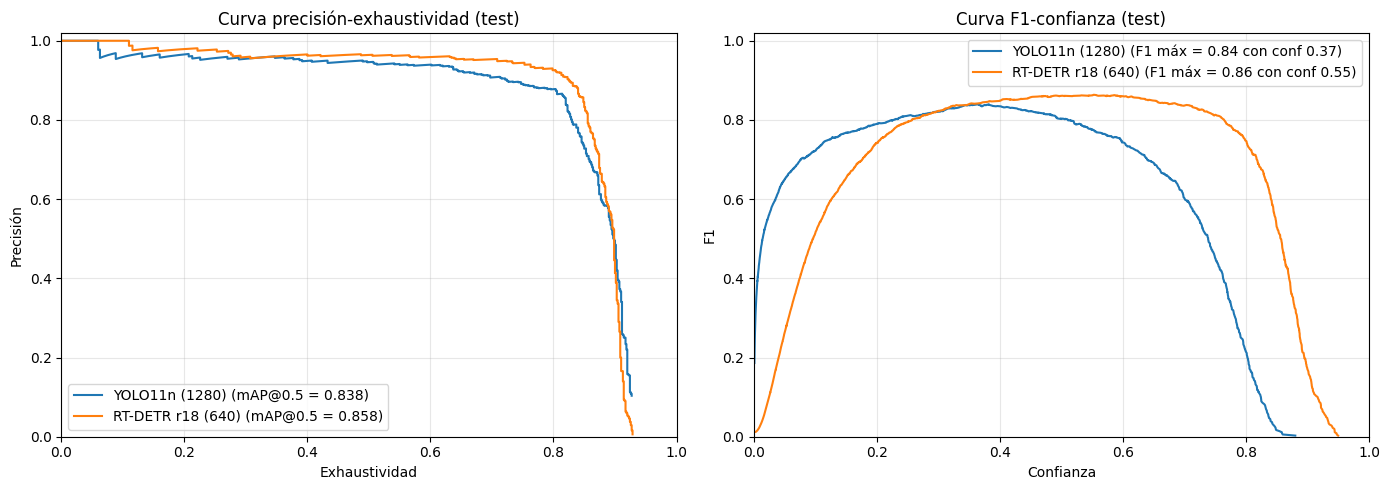

,mAP@0.5,mejor F1,conf óptima,precisión,exhaustividad,TP,FP,FN,ms/imagen
modelo,,,,,,,,,
YOLO11n (1280),0.838,0.839,0.366,0.866,0.814,570,88,130,19.074
RT-DETR r18 (640),0.858,0.864,0.553,0.909,0.823,576,58,124,33.631


In [ ]:
# Curvas a partir de las predicciones ordenadas por confianza
def curvas(r):
    o = np.argsort(-r["scores"])
    conf, tp = r["scores"][o], r["tp"][o]
    tp_acum, fp_acum = np.cumsum(tp), np.cumsum(~tp)
    recall = tp_acum / r["n_reales"]
    precision = tp_acum / (tp_acum + fp_acum)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    prec_envolvente = np.maximum.accumulate(precision[::-1])[::-1]  # interpolación tipo COCO
    ap50 = np.sum(np.diff(np.concatenate([[0], recall])) * prec_envolvente)
    return conf, precision, recall, f1, tp_acum, fp_acum, ap50


filas = []
fig, (ax_pr, ax_f1) = plt.subplots(1, 2, figsize=(14, 5))
for nombre, r in resultados.items():
    conf, prec, rec, f1, tp_acum, fp_acum, ap50 = curvas(r)
    k = int(np.argmax(f1))   # umbral con mejor F1
    filas.append({"modelo": nombre, "mAP@0.5": ap50, "mejor F1": f1[k], "conf óptima": conf[k],
                  "precisión": prec[k], "exhaustividad": rec[k],
                  "TP": int(tp_acum[k]), "FP": int(fp_acum[k]), "FN": r["n_reales"] - int(tp_acum[k]),
                  "ms/imagen": r["ms"]})
    ax_pr.plot(rec, prec, label=f"{nombre} (mAP@0.5 = {ap50:.3f})")
    ax_f1.plot(conf, f1, label=f"{nombre} (F1 máx = {f1[k]:.2f} con conf {conf[k]:.2f})")

ax_pr.set(title="Curva precisión-exhaustividad (test)", xlabel="Exhaustividad", ylabel="Precisión",
          xlim=(0, 1), ylim=(0, 1.02))
ax_f1.set(title="Curva F1-confianza (test)", xlabel="Confianza", ylabel="F1", xlim=(0, 1), ylim=(0, 1.02))
for ax in (ax_pr, ax_f1):
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("runs_rtdetr/comparativa_test_yolo_rtdetr.png", dpi=150)
plt.show()

display(pd.DataFrame(filas).set_index("modelo").round(3))